In [92]:
import pandas as pd
import numpy as np
import time
import seaborn as sns
import statsmodels as sm
import matplotlib.pyplot as plt

In [82]:
df = pd.read_csv('data/incidenti_comuni.csv')

In [83]:
df

,Nome Comune,Codice Comune,Area(kmq),Popolazione,Incidenti,Feriti,Morti,Anno
0,Agliè,1001,13.1462,2557,5,10,0,2001
1,Agliè,1001,13.1462,2538,5,10,0,2002
2,Agliè,1001,13.1462,2588,4,7,0,2003
3,Agliè,1001,13.1462,2679,9,13,0,2004
4,Agliè,1001,13.1462,2674,2,2,0,2005
...,...,...,...,...,...,...,...,...
190895,Villaspeciosa,111107,27.1937,2549,2,3,0,2020
190896,Villaspeciosa,111107,27.1943,2536,5,7,0,2021
190897,Villaspeciosa,111107,27.1943,2575,1,1,0,2022
190898,Villaspeciosa,111107,27.1943,2616,4,5,0,2023


### Duplicati

In [84]:
#la coppia codiceComune+anno deve essere unica.
df[df[['Codice Comune', 'Anno']].duplicated()]
#ogni Comune ha la righa 2024 doppia.
# l'errore era nel dataset SITUAS, nella colonna ANNO POPOLAZIONE aveva due volte il 2024.
# risolto facendo il merge con colonna SITUAS ANNO AREA che ha anni singoli.
df[df['Codice Comune'] == 1001]

,Nome Comune,Codice Comune,Area(kmq),Popolazione,Incidenti,Feriti,Morti,Anno
0,Agliè,1001,13.1462,2557,5,10,0,2001
1,Agliè,1001,13.1462,2538,5,10,0,2002
2,Agliè,1001,13.1462,2588,4,7,0,2003
3,Agliè,1001,13.1462,2679,9,13,0,2004
4,Agliè,1001,13.1462,2674,2,2,0,2005
5,Agliè,1001,13.1462,2662,1,1,0,2006
6,Agliè,1001,13.1462,2658,8,12,0,2007
7,Agliè,1001,13.1462,2638,5,10,0,2008
8,Agliè,1001,13.1462,2622,4,7,0,2009
9,Agliè,1001,13.1462,2615,7,14,0,2010


### Righe vuote

In [ ]:
df.isnull().sum()
# nome, area e popolazione arrivano da SITUAS che non trovano i codici in ISTAT
# 24 è un Comune di cui sappiamo tutto tranne il nome.

Nome Comune      24
Codice Comune     0
Area(kmq)         0
Popolazione       0
Incidenti         0
Feriti            0
Morti             0
Anno              0
dtype: int64

In [ ]:
d = df[df['Popolazione'].isnull()]
d = d[['Codice Comune']]
d.duplicated().sum()
# il codice Comune manca una sola volta, quindi per un anno solo.

np.int64(0)

In [86]:
df[df['Popolazione'].isnull()]
df[df['Codice Comune'] == 6064]
# non appare nel 2019 in quanto fuso a febbraio 2019. quindi non ci sono record geografici di un Comune che non c'è più.


,Nome Comune,Codice Comune,Area(kmq),Popolazione,Incidenti,Feriti,Morti,Anno
21695,Cuccaro Monferrato,6064,5.2191,364,0,0,0,2001
21696,Cuccaro Monferrato,6064,5.2191,356,0,0,0,2002
21697,Cuccaro Monferrato,6064,5.2191,371,0,0,0,2003
21698,Cuccaro Monferrato,6064,5.2191,360,0,0,0,2004
21699,Cuccaro Monferrato,6064,5.2191,367,1,1,0,2005
21700,Cuccaro Monferrato,6064,5.2191,354,0,0,0,2006
21701,Cuccaro Monferrato,6064,5.2191,343,0,0,0,2007
21702,Cuccaro Monferrato,6064,5.2191,354,0,0,0,2008
21703,Cuccaro Monferrato,6064,5.2191,351,0,0,0,2009
21704,Cuccaro Monferrato,6064,5.2191,343,0,0,0,2010


### N comuni negli anni

,Anno,Codice Comune
0,2001,8101
1,2002,8102
2,2003,8099
3,2004,8100
4,2005,8101
5,2006,8101
6,2007,8101
7,2008,8101
8,2009,7988
9,2010,8094


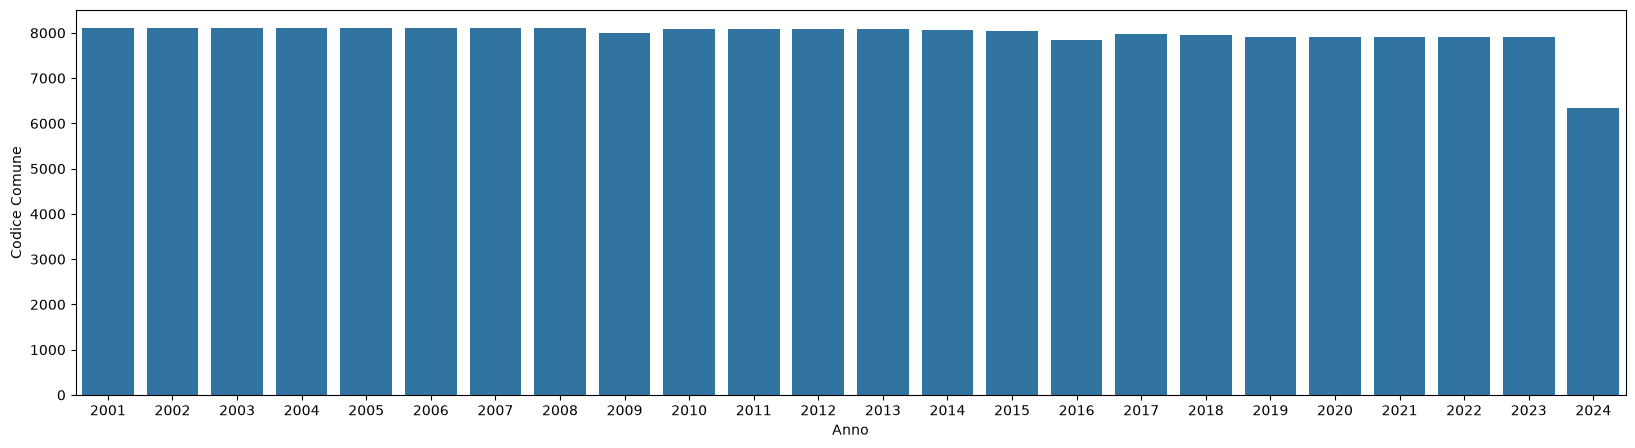

In [108]:
# il database ISTAT degli incidenti fornire per il 2024 6339 Comuni, mentre SITUAS il n° giusto: 7896
fig, ax = plt.subplots(figsize=(20, 5))
sns.barplot(x='Anno', y='Codice Comune', data=df.groupby('Anno', as_index=False)['Codice Comune'].count(), ax=ax)
df.groupby('Anno', as_index=False)['Codice Comune'].count()

In [ ]:
#Somme di incidenti per anno tornano. Come mi aspettavo avendo preso i dati dal API del ISTAT
df.groupby('Anno', as_index=False)['Incidenti'].sum()

,Anno,Incidenti
0,2001,263100
1,2002,265402
2,2003,252261
3,2004,243490
4,2005,240011
5,2006,238124
6,2007,230871
7,2008,218963
8,2009,210256
9,2010,212997


### Dati illogici
Non ci sono anni con 0 incidenti e morti/feriti > 0

In [122]:
df_copy = df[df['Incidenti'] == 0]
df_copy['mort&feriti'] = df['Feriti'] + df['Morti']
df_copy[df_copy['mort&feriti'] != 0]

,Nome Comune,Codice Comune,Area(kmq),Popolazione,Incidenti,Feriti,Morti,Anno,mort&feriti
